In [207]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [208]:
def f(x):
    return 3*x**2  - 4*x + 5

def dF(x):
    return 6*x-4

In [209]:
X=np.arange(-5,5,.25)
Y=f(X)

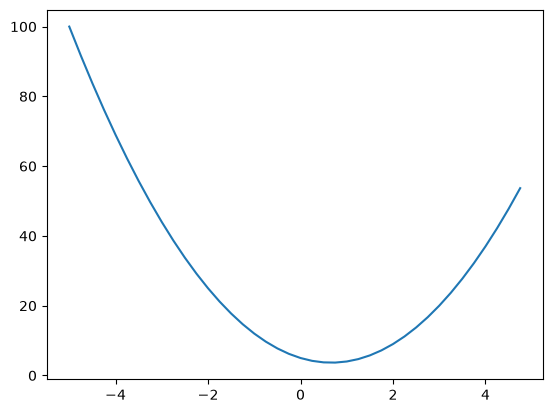

In [210]:
plt.plot(X,Y)

* instead of getting derivate in math sense we are getting intitute, where we try to see how small change in x lead to change in functionla change

In [211]:
h=0.00000000000001
x=3.0
(f(x+h)-f(x))/h

14.210854715202004

In [212]:
dF(3)

14

* we want to understand slop nature to know if we have to go down the gradient or up the gradient, rather than active derivate so we use limit formula 

$$Lim_{h\rightarrow0}\frac{f(x+h)-f(x)}{h}$$

In [213]:
a=2
b=-3
c=10
D=lambda a,b,c:a*b+c
d=D(a,b,c)

In [214]:
h=0.0001

a=2
b=-3
c=10
d1=D(a,b,c)

d1_da=(D(a+h,b,c)-D(a,b,c))/h
d1_db=(D(a,b+h,c)-D(a,b,c))/h
d1_dc=(D(a,b,c+h)-D(a,b,c))/h

In [215]:
print(d1_da,d1_db,d1_dc)

-3.000000000010772 2.0000000000042206 0.9999999999976694


In [216]:
class Value:
    def __init__(self,data,_children=(),_op='',label=''):
        self.data=data
        self.grad=0
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data}))"
    def __add__(self,other):
        return Value(self.data+other.data,(self,other),'add')
    def __mul__(self,other):
        return Value(self.data*other.data,(self,other),'mul')

In [217]:
a=Value(2,label='a')
b=Value(-3,label='b')
c=Value(10,label='c')
e=a*b
e.label='e'
d=e+c
d.label='d'
f=Value(-2,label='f')
L=d*f
L.label='L'

In [218]:
def test(h=0.0001):
    a=Value(2,label='a')
    b=Value(-3,label='b')
    c=Value(10,label='c')
    e=a*b
    e.label='e'
    d=e+c
    d.label='d'
    f=Value(-2,label='f')
    L=d*f
    L.label='L'
    

In [219]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

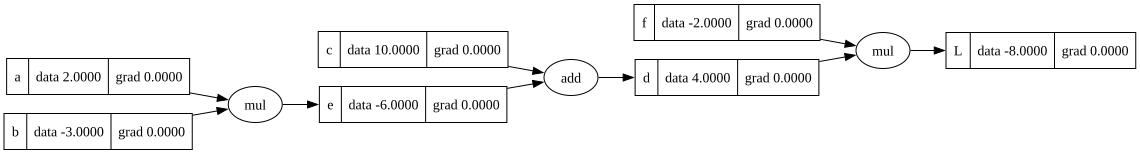

In [220]:
draw_dot(L)

In [221]:
class Value:
  
  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"
  
  def __add__(self, other):
    out = Value(self.data + other.data, (self, other), '+')
    
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    
    return out

  def __mul__(self, other):
    out = Value(self.data * other.data, (self, other), '*')
    
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
      
    return out
  
  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')
    
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    
    return out
  
  def backward(self):
    
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    
    self.grad = 1.0
    for node in reversed(topo):
      node._backward()


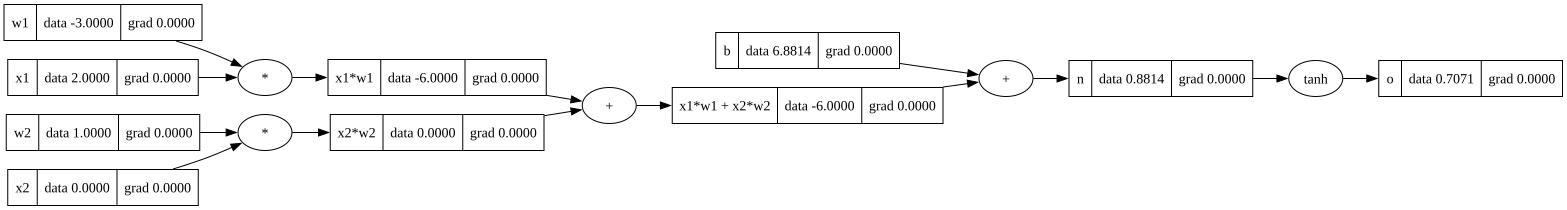

In [222]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
draw_dot(o)

In [223]:
o.backward()

In [224]:
x

3.0

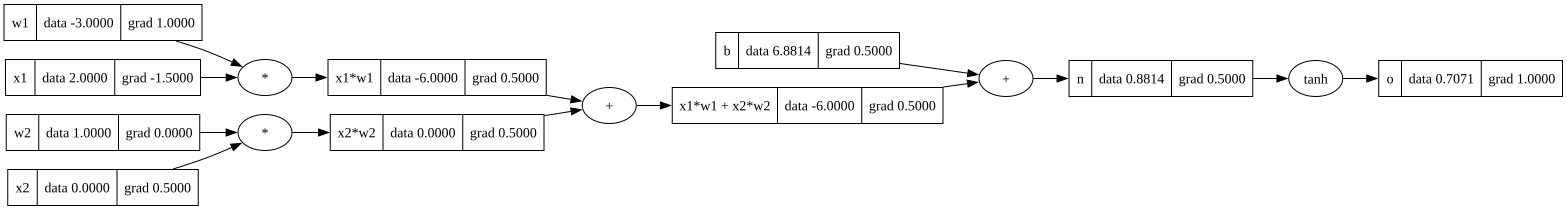

In [225]:
draw_dot(o)


In [226]:
class Value:
  
  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"
  
  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')
    
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    
    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')
    
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
      
    return out
  
  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
        self.grad += other * (self.data ** (other - 1)) * out.grad
    out._backward = _backward

    return out
  
  def __rmul__(self, other): # other * self
    return self * other

  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)

  def __radd__(self, other): # other + self
    return self + other

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')
    
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    
    return out
  
  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')
    
    def _backward():
      self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
    out._backward = _backward
    
    return out
  
  
  def backward(self):
    
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    
    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

In [227]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

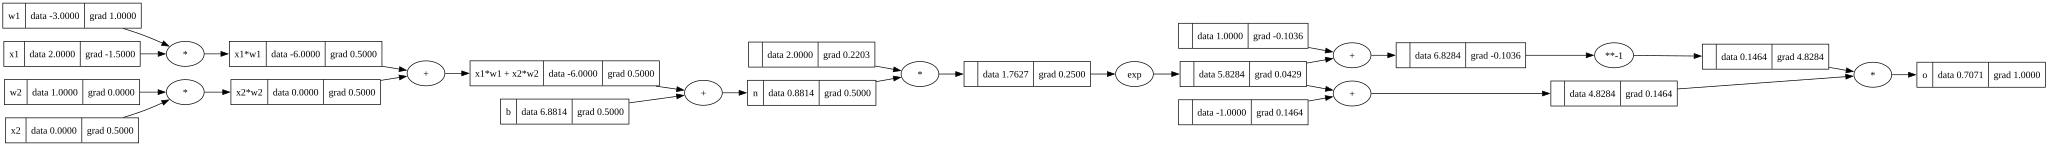

In [228]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
# ----
e = (2*n).exp()
o = (e - 1) / (e + 1)
# ----
o.label = 'o'
o.backward()
draw_dot(o)

In [229]:
import torch

In [230]:
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [231]:
help(torch.Tensor.backward)

Help on function backward in module torch._tensor:

backward(self, gradient=None, retain_graph=None, create_graph=False, inputs=None)
    Computes the gradient of current tensor wrt graph leaves.

    The graph is differentiated using the chain rule. If the tensor is
    non-scalar (i.e. its data has more than one element) and requires
    gradient, the function additionally requires specifying a ``gradient``.
    It should be a tensor of matching type and shape, that represents
    the gradient of the differentiated function w.r.t. ``self``.

    This function accumulates gradients in the leaves - you might need to zero
    ``.grad`` attributes or set them to ``None`` before calling it.
    See :ref:`Default gradient layouts<default-grad-layouts>`
    for details on the memory layout of accumulated gradients.

    .. note::

        If you run any forward ops, create ``gradient``, and/or call ``backward``
        in a user-specified CUDA stream context, see
        :ref:`Stream semant

In [232]:
from numpy import random
'''
nin:number of input neruons
nout:number of output neruons
'''
class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
    # w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b] # list append for pprint

class Layer:
    '''
    nin:number of input neruons toward layer
    nout:number of output neruons leaving layer 
    '''
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)] # this create input and out put nerons list for a single layer

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
        # return outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    '''
    nin: number of input neruons entering the first layer or input of the model
    nouts: list which contain number of output neurons for each layer, len(nouts) indicate number of layers, nout_i indicates number of output neurons for layer_i,
    loop takes care of previous output is input for next
    '''
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [233]:
x=Neuron(1)


In [234]:
list(zip(x.w,[8]))

[(Value(data=0.03490172712698891), 8)]

In [235]:
x([4])

Value(data=-0.35731018285524957)

In [236]:
x.b

Value(data=-0.5134059110988891)

In [237]:
x=Layer(3,1)
x

In [238]:
x([2,3,4])

Value(data=0.6192655434727257)

In [239]:
x = [2.0, 3.0, -1.0] # x1,x2,x3 for three input layers which goes through three layers where layer1,2 are hidden layer with 4 input and 4 output neuron with last output as 1 layer
n = MLP(3, [4, 4, 1])
n(x)

Value(data=0.12333952732788)

* how to train the network now basically how to apply gradient to each w_i

we now implement loss function on ypred

we now try to loss function

In [240]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets
ypred=[n(x) for x in xs]
print(ys)
print(ypred)

[1.0, -1.0, -1.0, 1.0]
[Value(data=0.12333952732788), Value(data=0.1278636551785677), Value(data=-0.024018568448513616), Value(data=0.30731306573869566)]


In [241]:
loss_each=[(yout-ygt)**2 for ygt,yout in zip(ys,ypred)]
loss=sum([(yout-ygt)**2 for ygt,yout in zip(ys,ypred)])

In [242]:
print(loss_each)
print(loss)

[Value(data=0.7685335843457048), Value(data=1.272076424672759), Value(data=0.9525397547332888), Value(data=0.4798151888963246)]
Value(data=3.472964952648077)


In [243]:
loss.backward()

In [244]:
n.layers[0].neurons[0].w[0].grad

0.34911982374026584

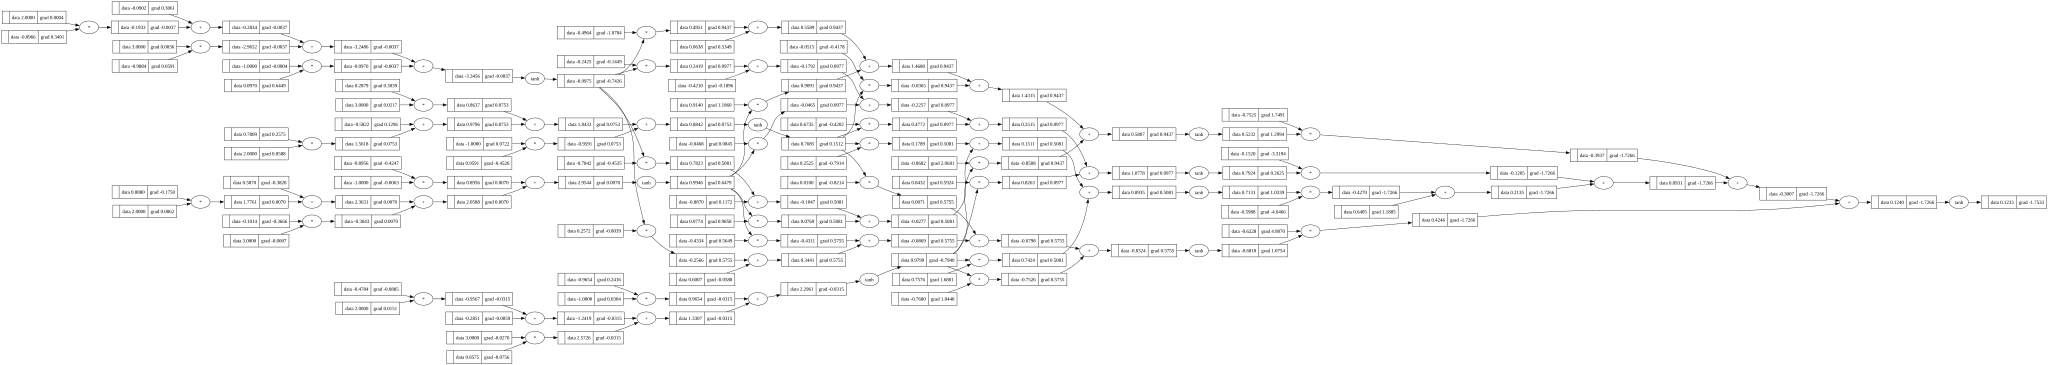

In [245]:
draw_dot(ypred[0])


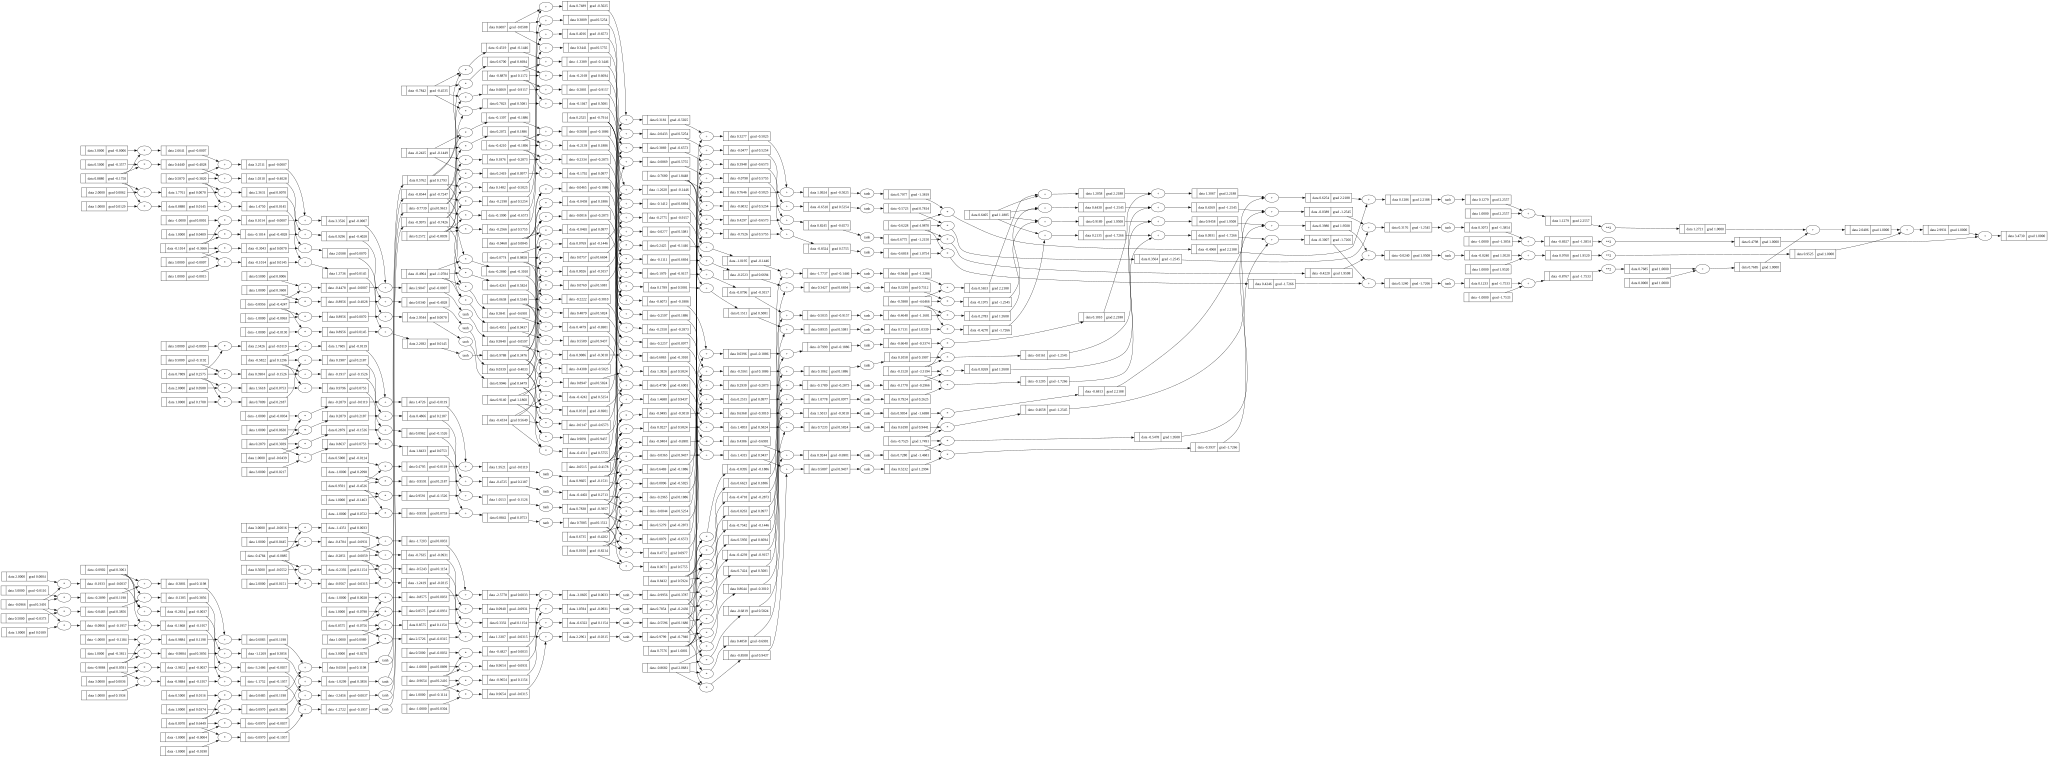

In [246]:
draw_dot(loss)

* first layer first neurons first weight has a grad, we will know how to edit what 
* we have grad for input data but we will not edit those one we will edit weights or values in hidden layers
* we will do gradient descent with step size toward p.grad
* gradient value points toward loss so increasing on the side of grad will increase the loss

so now we run calculate loss, run loss backward to get gradient values for each paramter then adujst the values and re run loss , this is forward (calcualte loss) pass and backward pass( getting gradient decendt) and we keep doing it till we reduce loss to zero or near zero

In [280]:
loss.backward()

In [281]:
stepSize=0.001
for p in n.parameters():
    p.data=p.data+stepSize*(p.grad*-1)

In [282]:
ypred=[n(x) for x in xs]
print(ys)
print(ypred)

[1.0, -1.0, -1.0, 1.0]
[Value(data=0.9321573298791733), Value(data=-0.8970517317729512), Value(data=-0.7656606689216283), Value(data=0.8667472436578153)]


In [283]:
loss_each=[(yout-ygt)**2 for ygt,yout in zip(ys,ypred)]
loss=sum([(yout-ygt)**2 for ygt,yout in zip(ys,ypred)])
print(loss_each)
print(loss)

[Value(data=0.004602627889123309), Value(data=0.010598345930948392), Value(data=0.054914922090258694), Value(data=0.017756297072789643)]
Value(data=0.08787219298312003)


* here as loop version

In [ ]:
n = MLP(3, [4, 4, 1])

In [293]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets
stepSize=0.001
for _iter_ in range(1000):
    # forward pass
    ypred=[n(x) for x in xs]
    loss_each=[(yout-ygt)**2 for ygt,yout in zip(ys,ypred)]
    loss=sum(loss_each)
    
    # backward pass
    for p in n.parameters():
        p.grad=0 # bug as if we dont 0 set the grads, then it grads gets added up and we move away from data as soon as we move away from valley, otherwise once we away from valley we will never go back

    loss.backward()
    # update
    for p in n.parameters():
        p.data+=stepSize*(-1*p.grad)
    
print(f'{_iter_}\t{loss.data}')

999	0.019385232670956012
